# NBA Championship History: A Data Visualization Project

**Author:** Charlie Buckman  
**Dataset:** NBA championship titles by franchise, through the 2024 NBA Finals  
**Scope:** Six selected franchises; historical championships are assigned to the franchise, including prior city names.

**Source:** NBA championship history / franchise records (https://www.nba.com/history/finals/champions). Values are a curated historical snapshot, not a live feed. The Warriors total includes Philadelphia and Golden State championships; Lakers total includes Minneapolis titles.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

records = [
    ('Boston Celtics', 18, 2024),
    ('Los Angeles Lakers', 17, 2020),
    ('Golden State Warriors', 7, 2022),
    ('Chicago Bulls', 6, 1998),
    ('San Antonio Spurs', 5, 2014),
    ('Miami Heat', 3, 2013),
]
df = pd.DataFrame(records, columns=['Franchise', 'Championships', 'Most recent title'])
df['Share of selected titles'] = df['Championships'] / df['Championships'].sum()
display(df)

,Franchise,Championships,Most recent title,Share of selected titles
0,Boston Celtics,18,2024,0.321429
1,Los Angeles Lakers,17,2020,0.303571
2,Golden State Warriors,7,2022,0.125000
3,Chicago Bulls,6,1998,0.107143
4,San Antonio Spurs,5,2014,0.089286
5,Miami Heat,3,2013,0.053571


## Visualization 1: Annotated bar chart

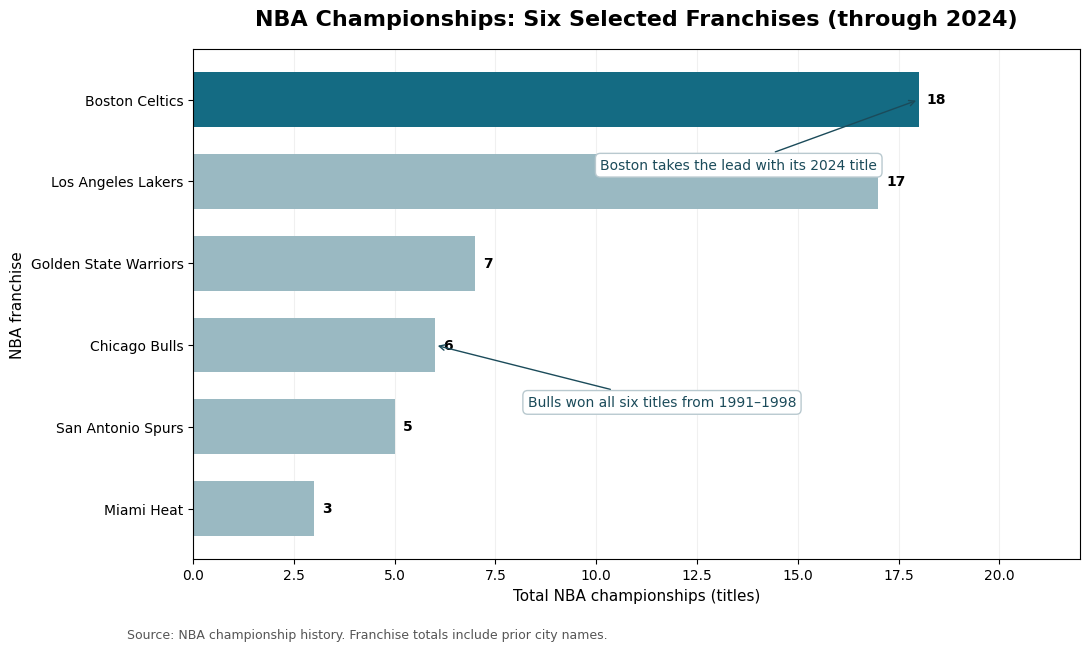

In [2]:
fig, ax = plt.subplots(figsize=(11, 6.5))
colors = ['#146b83' if x == 'Boston Celtics' else '#9ab9c2' for x in df['Franchise']]
bars = ax.barh(df['Franchise'][::-1], df['Championships'][::-1], color=colors[::-1], height=.67)
ax.set_title('NBA Championships: Six Selected Franchises (through 2024)', fontsize=16, weight='bold', pad=17)
ax.set_xlabel('Total NBA championships (titles)', fontsize=11)
ax.set_ylabel('NBA franchise', fontsize=11)
ax.set_xlim(0, 22)
ax.grid(axis='x', alpha=.18)
ax.set_axisbelow(True)
for bar in bars:
    ax.text(bar.get_width()+.2, bar.get_y()+bar.get_height()/2, f'{int(bar.get_width())}', va='center', weight='bold')
ax.annotate('Boston takes the lead with its 2024 title', xy=(18,5), xytext=(10.1,4.15),
            arrowprops=dict(arrowstyle='->', color='#1b4b5a'), fontsize=10, color='#1b4b5a',
            bbox=dict(boxstyle='round,pad=.35', fc='white', ec='#b9c9cf'))
ax.annotate('Bulls won all six titles from 1991–1998', xy=(6,2), xytext=(8.3,1.25),
            arrowprops=dict(arrowstyle='->', color='#1b4b5a'), fontsize=10, color='#1b4b5a',
            bbox=dict(boxstyle='round,pad=.35', fc='white', ec='#b9c9cf'))
fig.text(.12,.01,'Source: NBA championship history. Franchise totals include prior city names.', fontsize=9, color='#555')
fig.tight_layout(rect=[0,.04,1,1])
fig.savefig('annotated_championships.png', dpi=170, bbox_inches='tight')
plt.show()

## Visualization 2: Directly labeled dot plot

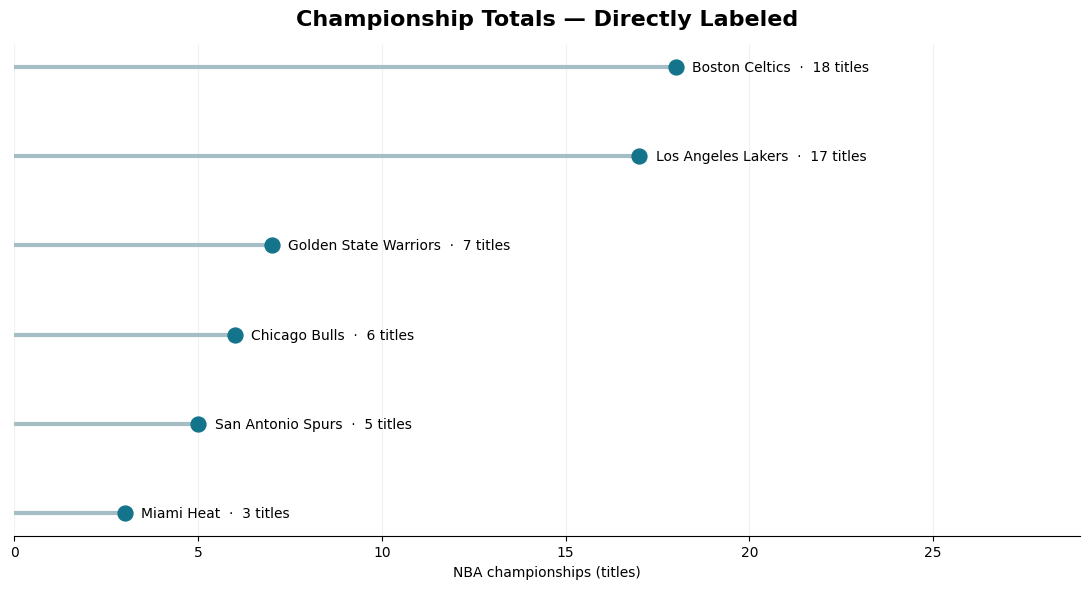

In [3]:
fig, ax = plt.subplots(figsize=(11, 6))
ordered = df.sort_values('Championships')
y = range(len(ordered))
ax.hlines(y, 0, ordered['Championships'], color='#a5bec6', linewidth=3)
ax.scatter(ordered['Championships'], y, s=115, color='#14748b', zorder=3)
for i, (_, r) in enumerate(ordered.iterrows()):
    ax.text(r['Championships']+.45, i, f"{r['Franchise']}  ·  {r['Championships']} titles", va='center', fontsize=10, weight='medium')
ax.set_yticks([])  # Direct labels beside marks replace a legend and category axis labels.
ax.set_xlim(0, 29)
ax.set_xlabel('NBA championships (titles)')
ax.set_title('Championship Totals — Directly Labeled', fontsize=16, weight='bold', pad=14)
ax.grid(axis='x', alpha=.17)
ax.spines[['top','right','left']].set_visible(False)
fig.tight_layout()
fig.savefig('direct_labeled_championships.png', dpi=170, bbox_inches='tight')
plt.show()

## Complementary formatted table

In [4]:
styled = (df.style
    .format({'Championships':'{:,.0f}', 'Most recent title':'{:.0f}', 'Share of selected titles':'{:.1%}'})
    .background_gradient(subset=['Championships'], cmap='Blues')
    .set_caption('Table 1. Championship counts and most recent wins (selected franchises)')
    .set_table_styles([
        {'selector':'caption','props':[('caption-side','top'),('font-weight','bold'),('font-size','15px'),('padding','10px')]},
        {'selector':'th','props':[('background-color','#123c50'),('color','white'),('padding','10px'),('text-align','left')]},
        {'selector':'td','props':[('padding','9px'),('border-bottom','1px solid #dbe5e9')]},
    ]).hide(axis='index'))
display(styled)

Franchise,Championships,Most recent title,Share of selected titles
Boston Celtics,18,2024,32.1%
Los Angeles Lakers,17,2020,30.4%
Golden State Warriors,7,2022,12.5%
Chicago Bulls,6,1998,10.7%
San Antonio Spurs,5,2014,8.9%
Miami Heat,3,2013,5.4%


## Reflection (149 words)

I chose horizontal bars for the first visualization because the franchise names are long and easier to read without rotation. The title identifies both the subject and the cutoff year, while the horizontal axis explicitly states that the values are championship counts rather than percentages. Numeric labels at the ends of the bars make exact comparisons possible without requiring readers to estimate positions. I added two annotations to call attention to meaningful historical patterns: Boston's 2024 lead and Chicago's concentrated championship era.

For the second chart, I used a directly labeled dot plot instead of a legend. Each franchise name and its total appear next to the corresponding point, reducing eye movement between the data and a separate key. The table complements the charts by adding the most recent championship year and each team's share of the six-franchise subtotal. That share is deliberately labeled as a selected-group measure, not a percentage of all NBA titles. Subtle color shading helps readers scan the counts.